<a href="https://colab.research.google.com/github/jyryu3161/2026CADD/blob/main/week7_LBVS_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RDKit 기반 Ligand-Based Virtual Screening (LBVS)
## Enamine Kinase Hinge Binders 24,000개 → Top 1,000

**수업 목표:** 활성 reference ligand의 SMILES를 입력하고 Enamine 라이브러리의 모든 화합물에 대해 **Morgan fingerprint (ECFP4에 해당: radius=2, 2048 bit) + Tanimoto similarity**를 계산하여 상위 1,000개를 선택합니다.

**학습 순서:** 환경 준비 → 라이브러리 업로드 → reference 설정 → 분자 파싱 → Fingerprint 검색 → Top 1,000 추출 → 분포 및 화합물 시각화 → CSV/SDF 저장.

> 이 노트북은 **VSFlow 없이 RDKit만 사용**합니다. 본 실습은 **2D fingerprint 기반 LBVS**이며 3D shape/pharmacophore screening이 아닙니다. 활성/비활성 라벨이 제공되지 않으므로 EF1%나 hit rate를 계산할 수 없고, 높은 Tanimoto similarity는 생물학적 활성을 보장하지 않습니다.

**데이터:** 수업에서 제공하는 `Enamine_Kinase_Hinge_Binders_Library_plated_24000cmpds_20261011.smiles` (실제 형식: tab-separated table).

## 1. 환경 준비


In [1]:
%pip -q install rdkit pandas matplotlib

from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import Draw, rdFingerprintGenerator
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("RDKit version:", rdBase.rdkitVersion)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 19.7 MB/s eta 0:00:00
RDKit version: 2026.09.1


## 2. Enamine SMILES 라이브러리 업로드
아래 셀 실행 후 제공받은 `.smiles` 파일을 업로드합니다. **파일 확장자는 .smiles이지만 탭으로 구분된 표**이며 첫 줄에 `SMILES`, `Catalog ID` 등의 헤더가 있습니다. Colab 밖의 Jupyter에서는 현재 작업 디렉터리에 파일을 두면 됩니다.

In [2]:
FILE_NAME = "Enamine_Kinase_Hinge_Binders_Library_plated_24000cmpds_20261011.smiles" # 추후 파일명 수정 필요
file_path = Path(FILE_NAME)

if not file_path.exists():
    try:
        from google.colab import files
        print("라이브러리 파일을 업로드하세요.")
        files.upload()
    except ImportError:
        print("Jupyter에서는 파일을 노트북과 같은 폴더에 넣으세요.")

if not file_path.exists():
    raise FileNotFoundError(f"파일을 찾을 수 없습니다: {FILE_NAME}")

library = pd.read_csv(file_path, sep="\t", dtype={"Catalog ID": str})
required_columns = ["SMILES", "Catalog ID"]
for column in required_columns:
    if column not in library.columns:
        raise ValueError(f"'{column}' 열이 없습니다. 파일 형식을 확인하세요.")

print(f"입력 화합물: {len(library):,}개")
print("열 이름:", list(library.columns))
display(library.head(3))

라이브러리 파일을 업로드하세요.


Saving Enamine_Kinase_Hinge_Binders_Library_plated_24000cmpds_20261011.smiles to Enamine_Kinase_Hinge_Binders_Library_plated_24000cmpds_20261011.smiles
입력 화합물: 24,000개
열 이름: ['SMILES', 'Catalog ID', 'MW', 'MW (desalted)', 'ClogP', 'logS', 'HBD', 'HBA', 'TPSA', 'RotBonds', 'Diverse Analogs from REAL', 'Close Analogs from REAL']


,SMILES,Catalog ID,MW,MW (desalted),ClogP,logS,HBD,HBA,TPSA,RotBonds,Diverse Analogs from REAL,Close Analogs from REAL
0,CC(NC=1C=CC=2CNC(=O)C2C1)C=3C=CC(=CC3)S(C)(=O)=O,Z1612627196,330.403,330.403,0.798,-3.157,2,4,75.27,4,https://real.enamine.net/public-enum-files/Z16...,https://real.enamine.net/public-enum-files/ged...
1,COC=1C=CC(OC(C)C)=C(C1)NC2CCC3(CC2)C(=O)NC=4C=...,Z1612767514,380.481,380.481,3.991,-4.240,2,4,59.59,5,https://real.enamine.net/public-enum-files/Z16...,https://real.enamine.net/public-enum-files/ged...
2,O=C(NC=1C=CC=C(Br)C1)C(=O)NC2CCN(CC2)C=3N=CC=CN3,Z438976308,404.261,404.261,0.658,-4.840,2,5,87.22,6,https://real.enamine.net/public-enum-files/Z43...,https://real.enamine.net/public-enum-files/ged...


## 3. Reference 화합물 선택
**학생 실습에서 변경할 변수는 `REFERENCE_SMILES`입니다.** 기본 예시: Gefitinib (EGFR inhibitor). SMILES를 바꾸면 다른 reference로 다시 검색할 수 있습니다.

Reference: Gefitinib
SMILES: COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1


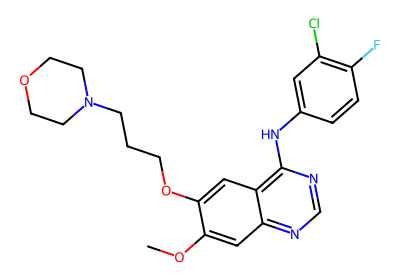

In [3]:
REFERENCE_NAME = "Gefitinib" # 변경
REFERENCE_SMILES = "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1" # 변경
TOP_N = 1000

reference_mol = Chem.MolFromSmiles(REFERENCE_SMILES)
if reference_mol is None:
    raise ValueError("Reference SMILES를 RDKit이 읽지 못했습니다.")

print("Reference:", REFERENCE_NAME)
print("SMILES:", Chem.MolToSmiles(reference_mol))
display(Draw.MolToImage(reference_mol, size=(400, 280)))

## 4. 라이브러리 분자 파싱
유효하지 않은 SMILES는 분석에서 제외하고 개수를 출력합니다. 기존 `Catalog ID`, `MW`, `ClogP` 등의 열은 그대로 보존합니다.

In [4]:
molecules = []
valid_indices = []
invalid_indices = []

for index, smiles in enumerate(library["SMILES"]):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        invalid_indices.append(index)
    else:
        molecules.append(mol)
        valid_indices.append(index)

valid_library = library.iloc[valid_indices].copy().reset_index(drop=True)
print(f"유효 분자: {len(molecules):,}개")
print(f"잘못된 SMILES: {len(invalid_indices):,}개")

if len(molecules) == 0:
    raise ValueError("유효한 SMILES가 없습니다.")

유효 분자: 24,000개
잘못된 SMILES: 0개


## 5. Morgan fingerprint + Tanimoto 유사도 계산
**ECFP4**는 여기서 Morgan radius=2, 2048-bit fingerprint로 구현합니다. Tanimoto는 두 비트 집합의 교집합/합집합에 대응하며 0~1 사이 값입니다. 참고: hashed 2048-bit 표현이므로 비트 충돌이 발생할 수 있습니다.

In [5]:

fingerprint_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
reference_fp = fingerprint_generator.GetFingerprint(reference_mol)

library_fps = []
for mol in molecules:
    library_fps.append(fingerprint_generator.GetFingerprint(mol))

similarity_scores = DataStructs.BulkTanimotoSimilarity(reference_fp, library_fps)

results = valid_library.copy()
results["Tanimoto_ECFP4"] = similarity_scores
results = results.sort_values("Tanimoto_ECFP4", ascending=False).reset_index(drop=True)
results.insert(0, "Rank", range(1, len(results) + 1))

top_results = results.head(TOP_N).copy()

print(f"검색 화합물: {len(results):,}개")
print(f"선택한 후보: {len(top_results):,}개")
print(f"최고 similarity: {top_results['Tanimoto_ECFP4'].iloc[0]:.4f}")
print(f"Top {len(top_results):,} 기준 similarity: {top_results['Tanimoto_ECFP4'].iloc[-1]:.4f}")
display(top_results[["Rank", "Catalog ID", "SMILES", "Tanimoto_ECFP4"]].head(10))

검색 화합물: 24,000개
선택한 후보: 1,000개
최고 similarity: 0.4627
Top 1,000 기준 similarity: 0.2118


,Rank,Catalog ID,SMILES,Tanimoto_ECFP4
0,1,Z1730496525,COC=1C=C2C(=NC=NC2=CC1F)NC=3C=CC(F)=CC3,0.462687
1,2,Z645423350,ClC=1C=CC=2C(=NC=NC2C1)NCCCCN3CCOCC3,0.458333
2,3,Z1695663917,COC=1C=CC(=CC1)NC=2N=CN=C3C=C(F)C(=CC23)OC,0.455882
3,4,Z729046124,FC=1C=CC=2N=CN=C(NCCCCN3CCOCC3)C2C1,0.438356
4,5,Z118332870,COC=1C=C2N=CN=C(NCCOC=3C=CC=CC3F)C2=CC1OC,0.430556
5,6,Z1695665314,COC1=CC=2C(=NC=NC2C=C1F)NCCCN3CC(C)OC(C)C3,0.423077
6,7,Z1874024228,COCCOC=1C=CC(=CC1Cl)NC=2N=CN=C3C(F)=CC=CC23,0.421053
7,8,Z1874286800,COC=1C=C(C=CC1F)NC=2N=CN=C3C=CC(=CC23)S(C)(=O)=O,0.413333
8,9,Z729046120,BrC=1C=CC=2N=CN=C(NCCCCN3CCOCC3)C2C1,0.405405
9,10,Z915928890,C=1C=CC2=C(N=CN=C2C1)NC=3C=CC=C(C3)CN4CCOCC4,0.400000


## 6. 결과 분석 및 시각화
전체 라이브러리와 Top 1,000의 similarity 분포를 비교합니다. 이것은 **활성 예측 정확도 그래프가 아니라 reference와의 화학구조 유사도 분포**입니다.

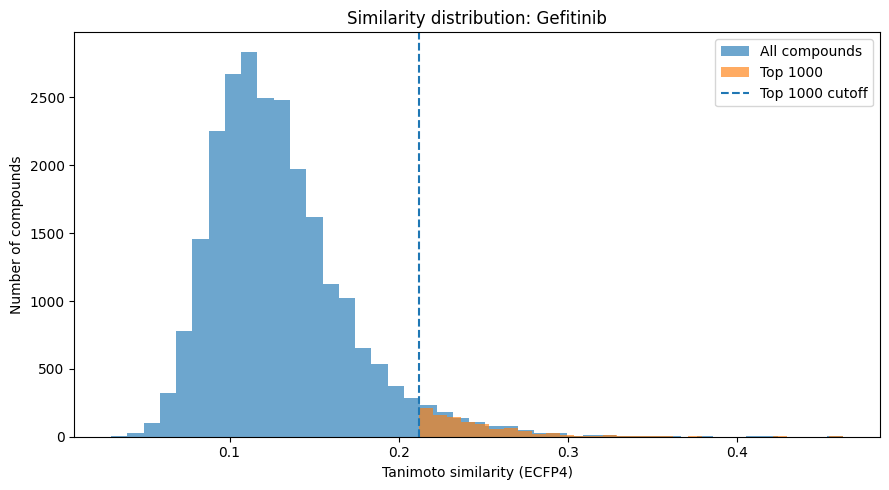

In [6]:
plt.figure(figsize=(9, 5))
plt.hist(results["Tanimoto_ECFP4"], bins=45, alpha=0.65, label="All compounds")
plt.hist(top_results["Tanimoto_ECFP4"], bins=30, alpha=0.65, label="Top 1000")
plt.axvline(top_results["Tanimoto_ECFP4"].iloc[-1], linestyle="--", label="Top 1000 cutoff")
plt.xlabel("Tanimoto similarity (ECFP4)")
plt.ylabel("Number of compounds")
plt.title(f"Similarity distribution: {REFERENCE_NAME}")
plt.legend()
plt.tight_layout()
plt.show()

### Top 12 화합물 구조 확인
각 화합물에 Catalog ID와 Tanimoto score를 표시합니다.

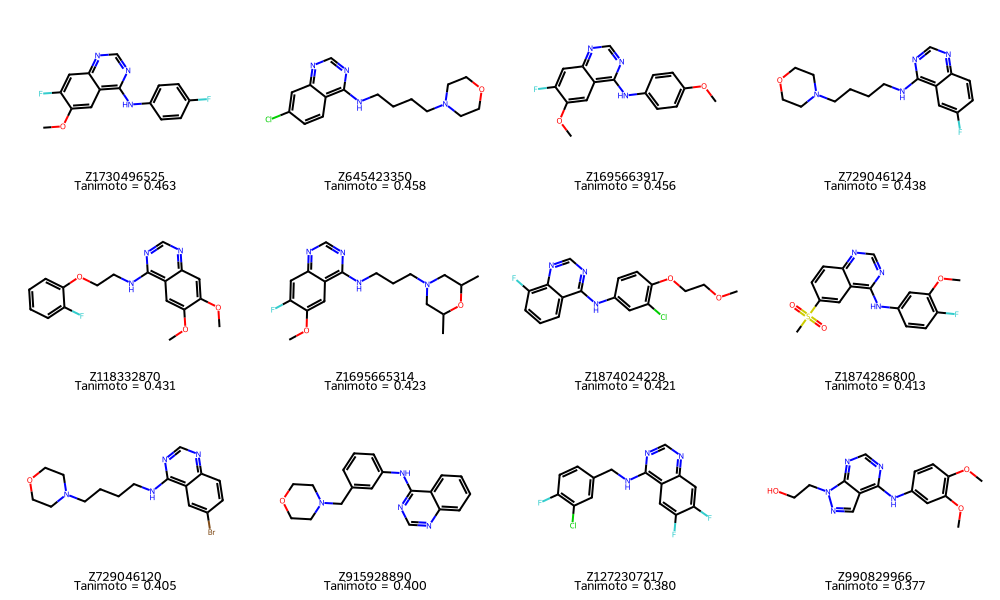

In [7]:
top_molecules = []
legends = []
for _, row in top_results.head(12).iterrows():
    top_molecules.append(Chem.MolFromSmiles(row["SMILES"]))
    legends.append(f"{row['Catalog ID']}\nTanimoto = {row['Tanimoto_ECFP4']:.3f}")

image = Draw.MolsToGridImage(top_molecules, molsPerRow=4, subImgSize=(250, 200), legends=legends)
display(image)

## 7. Top 1,000 화합물 CSV 및 SDF 저장
CSV에는 원본 Enamine 열과 `Rank`, `Tanimoto_ECFP4`를 유지합니다. SDF에는 **2D 좌표**를 기록합니다. Docking에 사용할 3D conformer는 포함되지 않습니다.

In [8]:
safe_name = "".join(char if char.isalnum() else "_" for char in REFERENCE_NAME)
csv_name = f"{safe_name}_Enamine_Top{len(top_results)}_RDKit.csv"
sdf_name = f"{safe_name}_Enamine_Top{len(top_results)}_2D.sdf"

# 엑셀에서도 열기 편한 CSV
top_results.to_csv(csv_name, index=False, encoding="utf-8-sig")

In [9]:
writer = Chem.SDWriter(sdf_name)
for _, row in top_results.iterrows():
    mol = Chem.MolFromSmiles(row["SMILES"])
    if mol is None:
        continue
    mol = Chem.Mol(mol)
    Chem.rdDepictor.Compute2DCoords(mol)
    mol.SetProp("_Name", str(row["Catalog ID"]))
    mol.SetProp("Catalog_ID", str(row["Catalog ID"]))
    mol.SetProp("Rank", str(row["Rank"]))
    mol.SetProp("Tanimoto_ECFP4", str(row["Tanimoto_ECFP4"]))
    writer.write(mol)
writer.close()

print("결과 파일:", csv_name, sdf_name)

try:
    from google.colab import files
    files.download(csv_name)
    files.download(sdf_name)
except ImportError:
    print("현재 폴더에서 파일을 확인하세요.")

결과 파일: Gefitinib_Enamine_Top1000_RDKit.csv Gefitinib_Enamine_Top1000_2D.sdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>